# Model comparison: CLIP, SigLIP, projection and the EfficientNet benchmark

Seven models classify the same 16 scene classes. Six are one-shot runs, one per config in `SigLIP_CLIP/configs/`: CLIP (ConvNeXt-B, LAION-400M) and SigLIP (ViT-B/16, WebLI), both frozen, each at three levels:

| level | config | text | image | projection |
|---|---|---|---|---|
| **1 prompt** | `*_general_noaug.yaml` | one prompt, `"a photo of a {}"` | the one-shot image only | off |
| **all prompts + aug** | `*_all_prompts_aug.yaml` | all 20 prompts per class | the one-shot image + 10 augmentations | off |
| **projection** | `*_projection.yaml` | all 20 prompts per class | the one-shot image + 10 augmentations | on |

The seventh is **EfficientNet-B0**, the supervised benchmark CNN (`Benchmark/efficientnet_b0_best.pt`), fine-tuned on ~1,900 labeled training images.

Every model is scored on the same images from `data/test` (400) and `data/train` (2,384). The 16 one-shot support images (seed 0) are left out of the train split for every model, so the counts match. `data/test2` is not used.

**Read the train column with care:** EfficientNet was trained on 80% of `data/train`, so most of those images are ones it has already seen. Only the **test** column is a fair comparison between the CNN and the one-shot models.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms as T
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix

sys.path.insert(0, "SigLIP_CLIP")
from projection import build_prototypes, load_model, predict
from train import ROOT, get_device, list_classes, load_config, pick_support_images
from evaluation import load_split

%matplotlib inline

device = get_device()
SPLITS = {"test": ROOT / "data/test", "train": ROOT / "data/train"}
SPLIT_COLORS = {"test": "#2a78d6", "train": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
print("device:", device)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps


## 1. Evaluation images
The same item lists are used for every model.

In [2]:
CONFIGS = {
    "CLIP 1 prompt": "clip_general_noaug",
    "CLIP all prompts + aug": "clip_all_prompts_aug",
    "CLIP + projection": "clip_projection",
    "SigLIP 1 prompt": "siglip_general_noaug",
    "SigLIP all prompts + aug": "siglip_all_prompts_aug",
    "SigLIP + projection": "siglip_projection",
}
RUNS = {name: load_config(ROOT / f"SigLIP_CLIP/configs/{file}.yaml") for name, file in CONFIGS.items()}
seeds = {cfg["train"]["seed"] for cfg in RUNS.values()}
assert len(seeds) == 1

classes = list_classes(ROOT / "data/train")
support = pick_support_images(ROOT / "data/train", classes, seeds.pop())
exclude = {str(p.relative_to(ROOT)) for p in support.values()}
items = {split: load_split(path, classes, exclude) for split, path in SPLITS.items()}
labels = {split: np.array([y for _, y in its]) for split, its in items.items()}

for split, its in items.items():
    print(f"{split:5s}: {len(its)} images, {len(classes)} classes")

test : 400 images, 16 classes
train: 2384 images, 16 classes


## 2. One-shot models: the six CLIP and SigLIP configs
Each run rebuilds its prototypes from its config, so the projection is retrained here (it takes a few seconds). All six use the same one-shot image per class.

In [3]:
preds, breakdown, loaded = {}, {}, {}
for name, cfg in RUNS.items():
    key = (cfg["model"]["name"], cfg["model"].get("pretrained"))
    if key not in loaded:
        loaded = {key: load_model(cfg, device)}
    model, preprocess, tokenizer = loaded[key]
    ck = build_prototypes(cfg, model, preprocess, tokenizer, device)
    preds[name], breakdown[name] = {}, {}
    for split, its in items.items():
        start = time.time()
        y, p = predict(cfg, model, preprocess, device, its, ck)
        assert (y == labels[split]).all()
        preds[name][split] = p["combined"]
        breakdown[name][split] = {kind: accuracy_score(y, v) for kind, v in p.items()}
        print(f"{name:26s} {split:5s} {breakdown[name][split]['combined']:.1%}  ({time.time() - start:.0f}s)")
del loaded, model

  Bedroom        image_0111.jpg  (1 image views, 1 prompts)
  Coast          image_0238.jpg  (1 image views, 1 prompts)
  Flower         image_0061.jpg  (1 image views, 1 prompts)
  Forest         image_0067.jpg  (1 image views, 1 prompts)
  Highway        image_0202.jpg  (1 image views, 1 prompts)


  Industrial     image_0235.jpg  (1 image views, 1 prompts)
  InsideCity     image_0169.jpg  (1 image views, 1 prompts)
  Kitchen        image_0078.jpg  (1 image views, 1 prompts)
  LivingRoom     image_0211.jpg  (1 image views, 1 prompts)
  Mountain       image_0180.jpg  (1 image views, 1 prompts)


  Office         image_0215.jpg  (1 image views, 1 prompts)
  OpenCountry    image_0056.jpg  (1 image views, 1 prompts)
  Store          image_0244.jpg  (1 image views, 1 prompts)
  Street         image_0036.jpg  (1 image views, 1 prompts)
  Suburb         image_0073.jpg  (1 image views, 1 prompts)
  TallBuilding   image_0036.jpg  (1 image views, 1 prompts)


CLIP 1 prompt              test  88.0%  (10s)


CLIP 1 prompt              train 86.1%  (56s)


  Bedroom        image_0111.jpg  (11 image views, 20 prompts)


... (80 outputs left out)

  epoch  240  loss 5.8427  (contrastive 5.0829, distance from identity 0.7598)


  epoch  300  loss 5.8234  (contrastive 5.0567, distance from identity 0.7667)


SigLIP + projection        test  91.2%  (7s)


SigLIP + projection        train 88.4%  (42s)


## 3. Benchmark CNN: EfficientNet-B0
The checkpoint holds a torchvision EfficientNet-B0 state dict with a 16-class head. Test images are resized to the training size (224 px) and normalized with the ImageNet mean and std from the checkpoint's config.

In [4]:
ckpt = torch.load(ROOT / "Benchmark/efficientnet_b0_best.pt", map_location="cpu", weights_only=False)
assert ckpt["class_names"] == classes

cnn = torchvision.models.efficientnet_b0()
cnn.classifier = nn.Sequential(nn.Dropout(ckpt["config"]["model"]["dropout"]), nn.Identity(), nn.Linear(1280, len(classes)))
cnn.load_state_dict(ckpt["model_state"])
cnn = cnn.to(device).eval()

data_cfg = ckpt["config"]["data"]
cnn_preprocess = T.Compose([
    T.Resize((data_cfg["img_size"], data_cfg["img_size"])),
    T.ToTensor(),
    T.Normalize(data_cfg["mean"], data_cfg["std"]),
])

@torch.no_grad()
def predict_cnn(its, batch_size=32):
    out = []
    for i in range(0, len(its), batch_size):
        batch = torch.stack([cnn_preprocess(Image.open(p).convert("RGB")) for p, _ in its[i:i + batch_size]])
        out.append(cnn(batch.to(device)).argmax(dim=1).cpu())
    return torch.cat(out).numpy()

CNN = "EfficientNet-B0"
preds[CNN] = {}
for split, its in items.items():
    start = time.time()
    preds[CNN][split] = predict_cnn(its)
    print(f"{CNN:26s} {split:5s} {accuracy_score(labels[split], preds[CNN][split]):.1%}  ({time.time() - start:.0f}s)")
print(f"best validation accuracy stored in the checkpoint: {ckpt['best_val_acc']:.1%}")

EfficientNet-B0            test  95.0%  (3s)


EfficientNet-B0            train 99.1%  (17s)
best validation accuracy stored in the checkpoint: 95.6%


## 4. Overall accuracy

In [5]:
MODELS = list(preds)
accuracy = pd.DataFrame({split: {m: accuracy_score(labels[split], preds[m][split]) for m in MODELS} for split in SPLITS})
accuracy.index.name = "model"
accuracy.style.format("{:.1%}").highlight_max(axis=0, props="font-weight: bold")

,test,train
model,,
CLIP 1 prompt,88.0%,86.1%
CLIP all prompts + aug,89.2%,87.8%
CLIP + projection,89.8%,89.0%
SigLIP 1 prompt,86.2%,82.4%
SigLIP all prompts + aug,88.8%,85.8%
SigLIP + projection,91.2%,88.4%
EfficientNet-B0,95.0%,99.1%


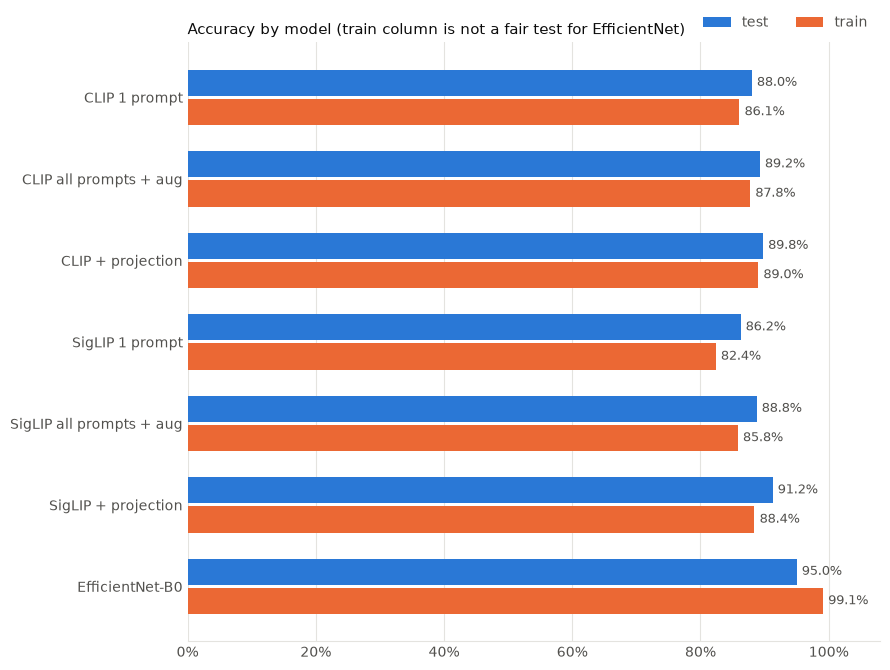

In [6]:
fig, ax = plt.subplots(figsize=(9, 6.8))
y = np.arange(len(MODELS))[::-1]
height = 0.36
for offset, split in zip([height / 2, -height / 2], SPLITS):
    values = accuracy[split].to_numpy()
    bars = ax.barh(y + offset, values, height=height - 0.04, color=SPLIT_COLORS[split], label=split)
    for bar, v in zip(bars, values):
        ax.text(v + 0.008, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", fontsize=9, color=MUTED)

ax.set_yticks(y, MODELS, color=INK)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(colors=MUTED, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, labelcolor=MUTED)
ax.set_title("Accuracy by model (train column is not a fair test for EfficientNet)", loc="left", color=INK, fontsize=11)
plt.tight_layout()
plt.show()

## 5. What each half of the one-shot prototype contributes
`text-only` uses only the prompt vectors (zero-shot with that config's prompts), `image-only` only the one-shot image vectors (with or without augmentations), `combined` their average (the method itself).

In [7]:
rows = {(m, kind): {split: breakdown[m][split][kind] for split in SPLITS}
        for m in breakdown for kind in ["text-only", "image-only", "combined"]}
parts = pd.DataFrame(rows).T
parts.index.names = ["model", "prototype"]
parts.style.format("{:.1%}")

## 6. Per-class accuracy on the test split
Each cell is the share of that class's 25 test images the model got right.

In [8]:
per_class = pd.DataFrame({
    m: confusion_matrix(labels["test"], preds[m]["test"], labels=range(len(classes))).diagonal() / 25
    for m in MODELS
}, index=classes)
per_class.loc["mean"] = per_class.mean()
per_class.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1, subset=pd.IndexSlice[classes, :])

,CLIP 1 prompt,CLIP all prompts + aug,CLIP + projection,SigLIP 1 prompt,SigLIP all prompts + aug,SigLIP + projection,EfficientNet-B0
Bedroom,100%,100%,100%,100%,100%,100%,96%
Coast,96%,100%,100%,96%,96%,96%,100%
Flower,100%,100%,100%,100%,100%,100%,100%
Forest,92%,96%,92%,96%,100%,100%,80%
Highway,100%,100%,100%,100%,100%,100%,100%
Industrial,88%,88%,92%,68%,68%,100%,92%
InsideCity,16%,32%,36%,40%,44%,44%,92%
Kitchen,100%,100%,100%,100%,100%,100%,96%
LivingRoom,96%,92%,96%,84%,92%,96%,92%
Mountain,92%,92%,96%,92%,92%,92%,88%


## 7. Confusion matrices on the test split

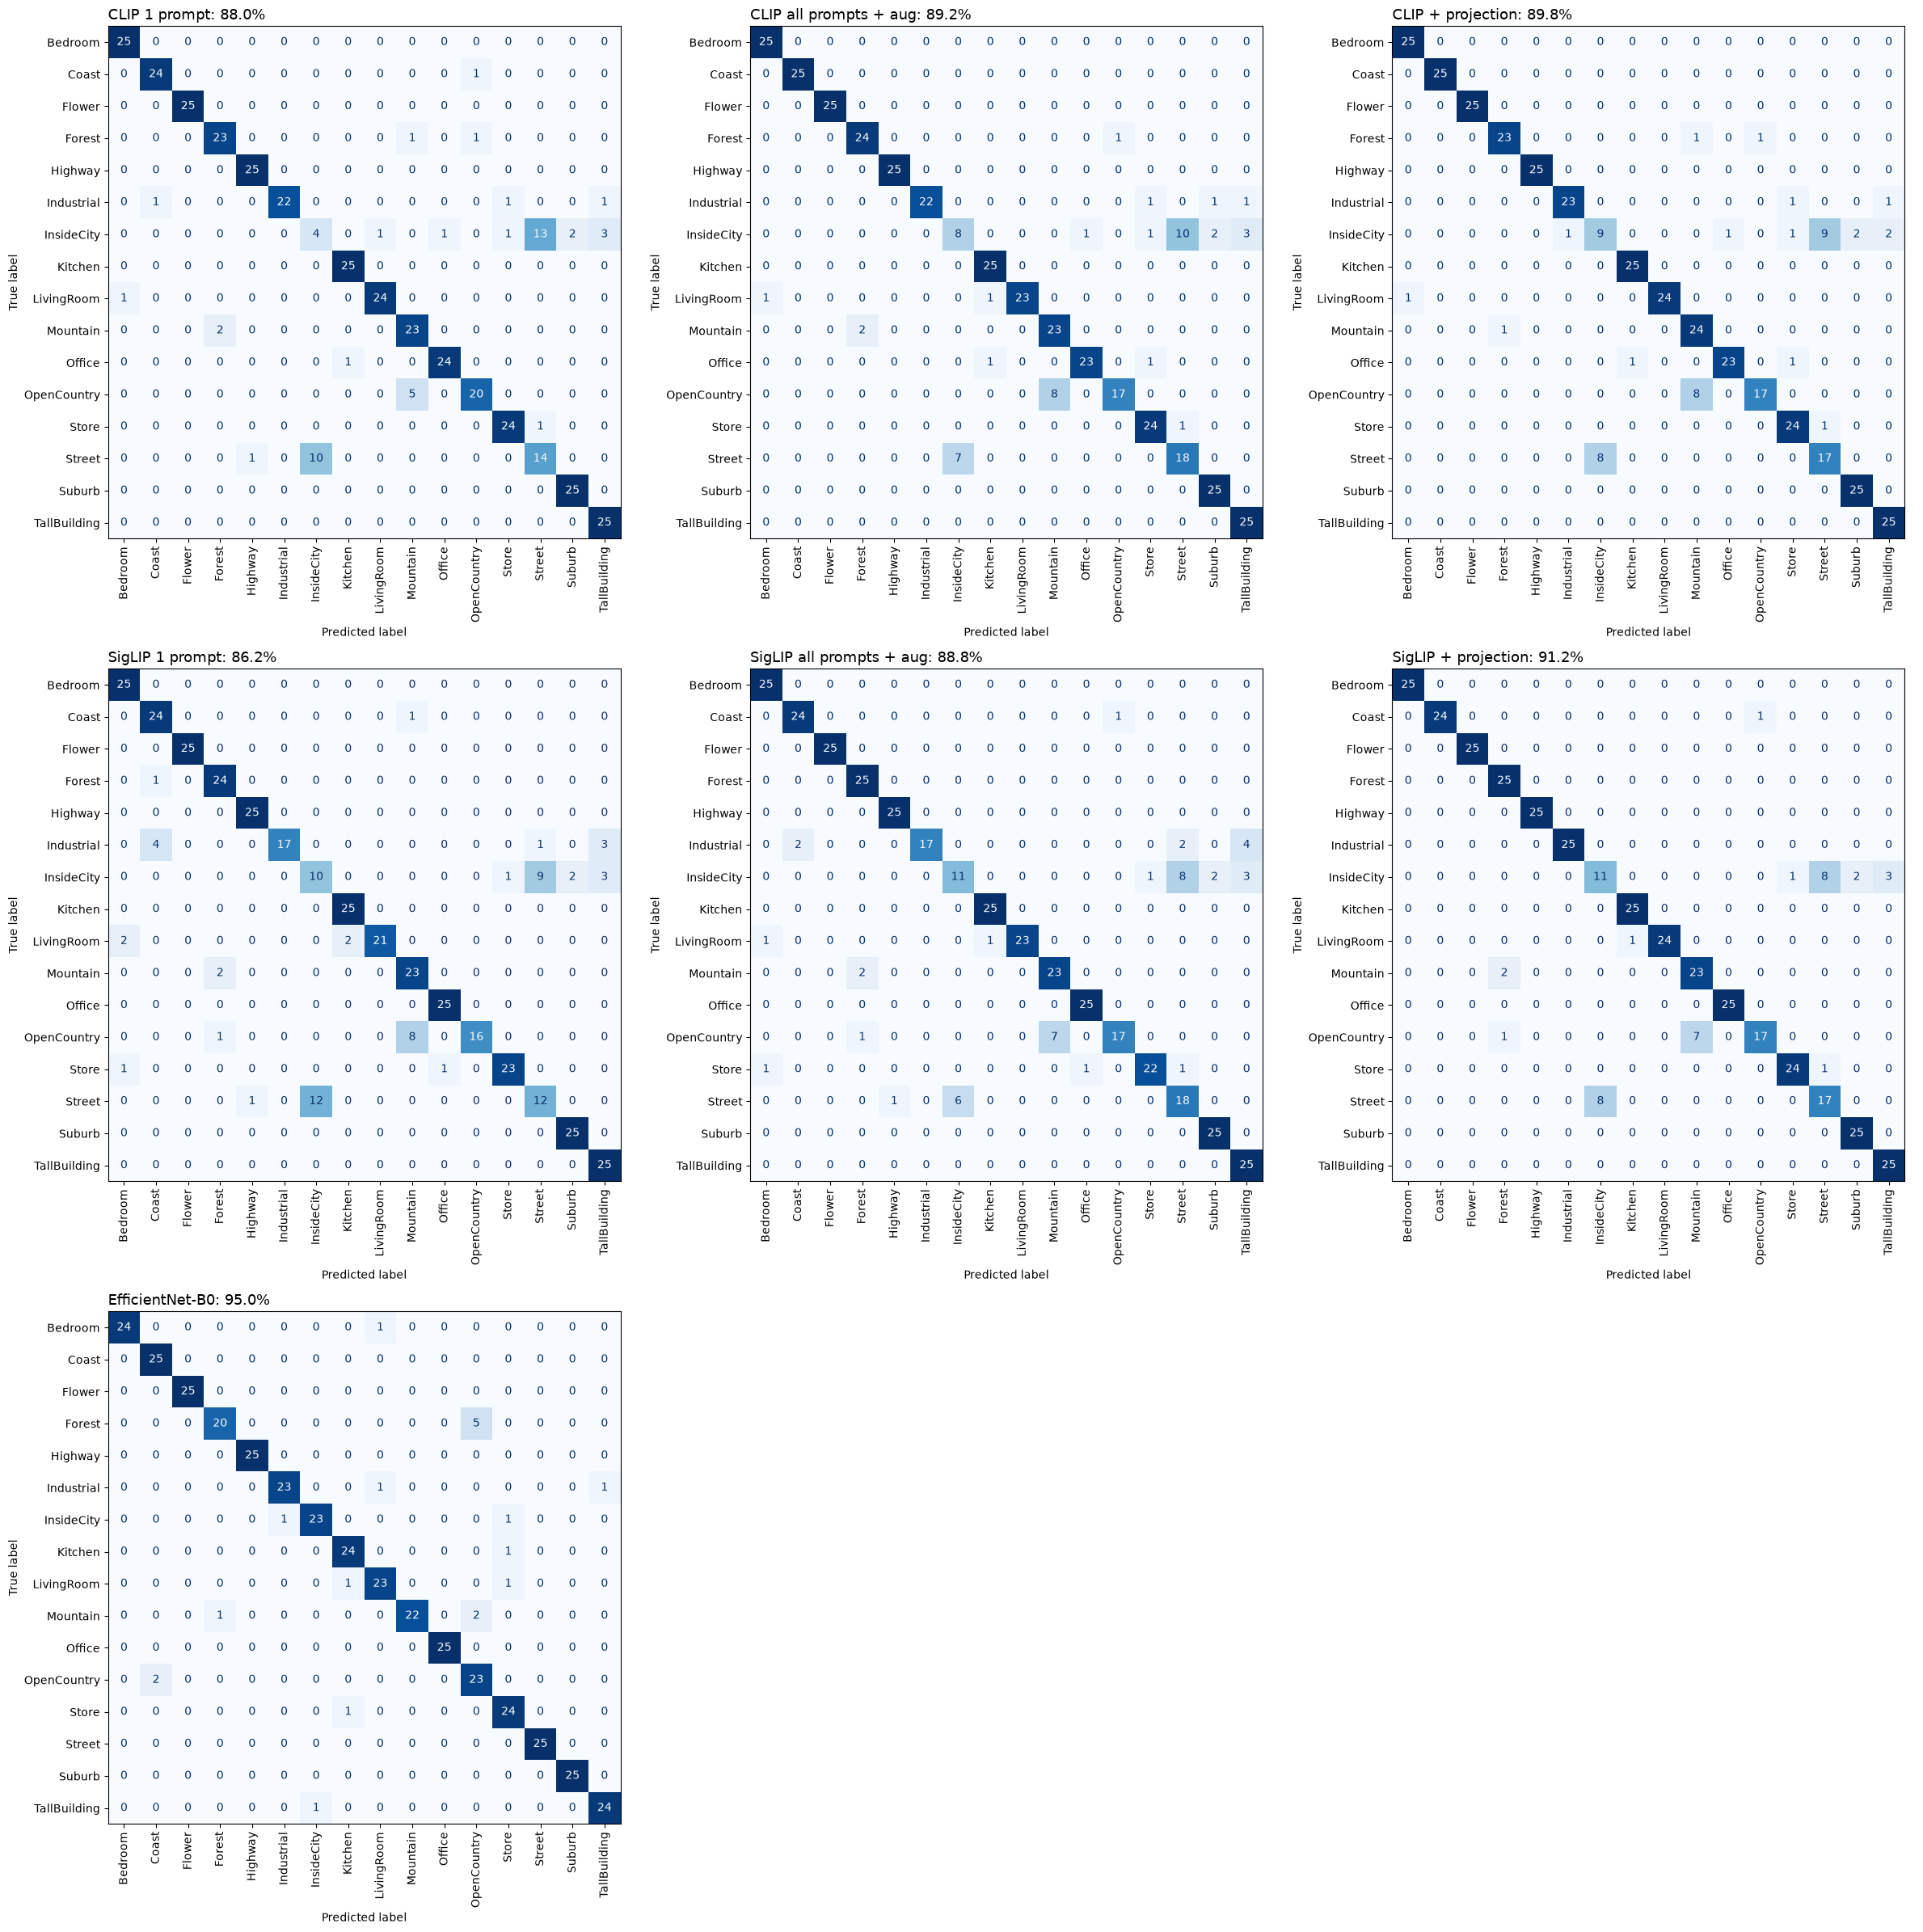

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(24, 24))
for ax, m in zip(axes.flat, MODELS):
    cm = confusion_matrix(labels["test"], preds[m]["test"], labels=range(len(classes)))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
    ax.set_title(f"{m}: {accuracy.loc[m, 'test']:.1%}", loc="left", fontsize=13)
for ax in axes.flat[len(MODELS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()